# Sources detection

In [1]:
import time
from astropy.coordinates import SkyCoord
from astropy.table import Table, vstack, unique
import astropy.units as u
import matplotlib.pyplot as plt 
import numpy as np 

from gammapy.maps import Map, MapCoord
from gammapy.datasets import Datasets
from gammapy.modeling.models import Models, PointSpatialModel, PowerLawSpectralModel, SkyModel, LogParabolaSpectralModel, GeneralizedGaussianSpatialModel
from gammapy.modeling import Fit
from gammapy.estimators import TSMapEstimator, ExcessMapEstimator
from gammapy.estimators.utils import get_combined_significance_maps
from gammapy.catalog import CATALOG_REGISTRY

/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Let's start by loading the combined significance map computed previously

In [2]:
sig_rcorr0p1 = Map.read("./datasets/rxj/maps/combined_significance_fermi_hess_rcorr0p1.fits.gz")

## Image filtering

Now we are going to use some technique from scikit-image to filter out the residual noise and keep only the significant excess.
Here we use a method called Hysteresis filtering. Two thresholds are used: first, pixels above the higher threshold are selected, and then pixels between the two thresholds are selected only if they are continuously connected to a pixel above the high threshold. 

See Also: https://scikit-image.org/docs/0.25.x/auto_examples/filters/plot_hysteresis.html

In [3]:
from skimage import filters

In [4]:
sig_low = 2
sig_hig = 4

hysteresis_mask  = filters.apply_hysteresis_threshold(sig_rcorr0p1,sig_low,sig_hig)
sig_rcorr0p1_fil = sig_rcorr0p1*hysteresis_mask

We can also used `scipy.ndimage` to label the structures isolated and remove those smaller than a given number of pixels

In [5]:
import scipy.ndimage as ndi
def filter_isolated_cells(map_, struct=None, Nmin=1):
    """ Return array with completely isolated single cells removed
    :param array: Array with completely isolated single cells
    :param struct: Structure array for generating unique regions
    :return: Array with minimum region size > Nmin
    """
    geom = map_.geom
    array = map_.data
    if struct is None:
        struct = [[0, 1, 0], [1, 1, 1], [0, 1, 0]]
    filtered_array = np.copy(array)
    id_regions, num_ids = ndi.label(filtered_array, structure=struct)
    id_sizes = np.array(ndi.sum(array, id_regions, range(num_ids + 1)))
    area_mask = id_sizes <= Nmin
    filtered_array[area_mask[id_regions]] = 0
    id_regions, num_ids = ndi.label(filtered_array, structure=struct)

    filtered_map = Map.from_geom(geom, data=filtered_array)
    id_regions = Map.from_geom(geom, data=id_regions)
    num_ids = Map.from_geom(geom, data=num_ids)

    return filtered_map, id_regions, num_ids

In [6]:
sig_rcorr0p1_fil_clean, id_regions, num_ids = filter_isolated_cells(sig_rcorr0p1_fil, struct=np.ones((3,3)), Nmin=10)


In [7]:
def plot_cutout(image, ax, plot_kwargs=None, margin=2*u.deg):
    image = image.cutout(
        image.geom.center_skydir, width=np.max(image.geom.width) - 2 * margin
    )
    kwargs = dict(ax=ax)
    if plot_kwargs : 
        kwargs.update(plot_kwargs)
    image.plot(**kwargs)


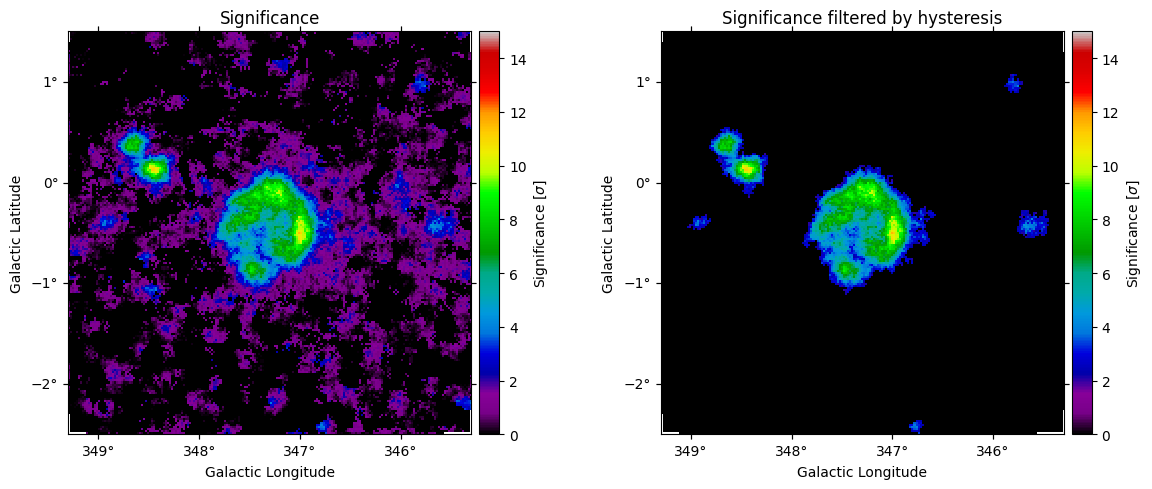

In [8]:
resi_fil_kwargs = dict(
    clim=[0, 15],
    cmap=plt.cm.nipy_spectral,
    add_cbar=True,
    kwargs_colorbar={"label": r"Significance [$\sigma$]"})

margin=2.*u.deg
geom = sig_rcorr0p1.geom
fig_geom = geom.cutout(geom.center_skydir, width=np.max(geom.width) - 2 * margin)

plt.figure(figsize=(12, 5))

ax1 = plt.subplot(121, projection=fig_geom.wcs)
plot_cutout(sig_rcorr0p1, ax1, resi_fil_kwargs, margin=margin)
ax1.set_title("Significance")


ax2 = plt.subplot(122, projection=fig_geom.wcs)
plot_cutout(sig_rcorr0p1_fil, ax2, resi_fil_kwargs, margin=margin)
ax2.set_title("Significance filtered by hysteresis")
, 
plt.tight_layout()

We can select and visualize the different structure using the `id_regions` created

<WCSAxes: >

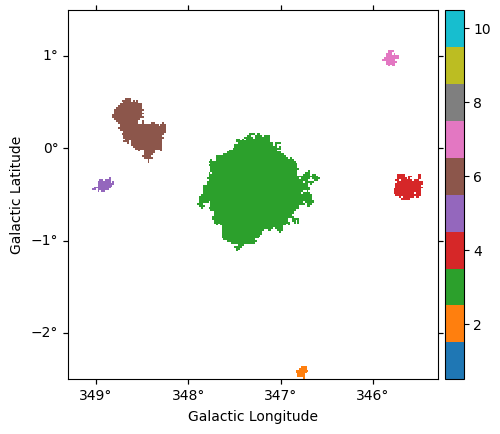

In [9]:
id_regions_cut = id_regions.cutout(
        id_regions.geom.center_skydir, width=np.max(id_regions.geom.width) - 2 * margin
    )
id_regions_cut.data = id_regions_cut.data.astype(float)
id_regions_cut.data[id_regions_cut<=1]=np.nan

id_regions_cut.plot(cmap=plt.cm.tab10, add_cbar=True, vmin=0.5, vmax=10.5)

## Object detection methods

Now let's apply some technique to localize the significance peak and derive a guess for the source size and try to split these structures in smaller pieces.

### Peak detection

Find local maxima separated from a given minimal distance

In [10]:
from gammapy.estimators.utils import find_peaks

In [11]:
peaks = find_peaks(sig_rcorr0p1_fil, threshold=4, min_distance="0.1 deg")
peaks

value,x,y,ra,dec
,,,deg,deg
float64,int64,int64,float64,float64
11.537,214,199,258.18017,-40.04539
11.255,141,230,258.63668,-38.49909
9.9255,204,220,257.89188,-39.63624
8.88,190,180,258.94854,-39.87821
8.3313,131,241,258.55804,-38.20825
6.3958,185,194,258.72817,-39.63387
4.4297,279,203,257.08051,-41.04449
4.2057,118,205,259.49755,-38.41454


In [12]:
peak_coords = SkyCoord(peaks["ra"], peaks["dec"], frame="icrs").galactic

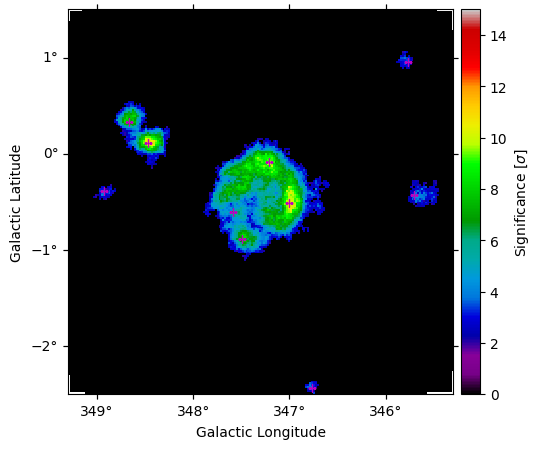

In [13]:
plt.figure(figsize=(7, 5))
ax = plt.subplot(111, projection=fig_geom.wcs)
plot_cutout(sig_rcorr0p1_fil, ax, resi_fil_kwargs)
ax.plot_coord(peak_coords, " m+")

###  Watershed Segmentation

Starting from user-defined markers, the watershed algorithm treats pixels values as a local topography (elevation). The algorithm floods basins from the markers until basins attributed to different markers meet on watershed lines

We generate markers at the local maxima of the significance and we run the watershed on the negative significance image.

See Also: https://scikit-image.org/docs/0.25.x/auto_examples/segmentation/plot_watershed.html

In [14]:
from skimage.segmentation import watershed

In [15]:
peak_map = Map.from_geom(sig_rcorr0p1_fil.geom, data=False)
for ix, iy in zip(peaks["x"], peaks["y"]):
    peak_map.data[iy, ix] = True #TODO: is the order correct or a bug ?
markers, _ = ndi.label(peak_map.data)

In [16]:
image = sig_rcorr0p1_fil.data
image[~np.isfinite(image)] = 0.
watershed_labels = watershed(-image, markers = markers, mask=image)
id_regions_watershed =  Map.from_geom(sig_rcorr0p1_fil.geom, data=watershed_labels.astype(float))

<WCSAxes: >

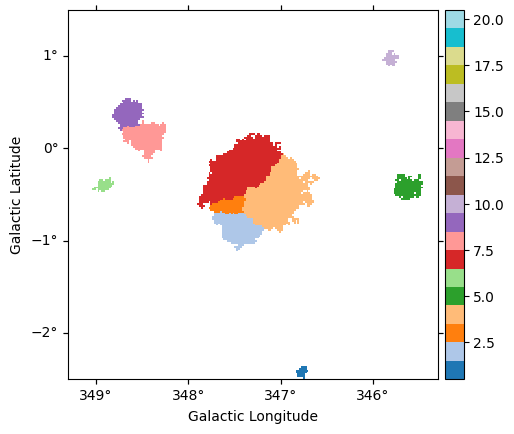

In [17]:
id_regions_watershed_cut = id_regions_watershed.cutout(
        id_regions_watershed.geom.center_skydir, width=np.max(id_regions_watershed.geom.width) - 2 * margin
    )
id_regions_watershed_cut.data[id_regions_watershed_cut==0]=np.nan

id_regions_watershed_cut.plot(cmap=plt.cm.tab20, add_cbar=True, vmin=0.5, vmax=20.5)

### Regions properties

We can measure the size of the regions isolated with `skimage.measure.regionprops`.

See Also: https://scikit-image.org/docs/0.25.x/auto_examples/segmentation/plot_regionprops.html#measure-region-properties

In [18]:
from skimage.measure import regionprops, regionprops_table

In [19]:
props_generator = regionprops(id_regions_cut.data.astype(int))


props_table = regionprops_table(id_regions_cut.data.astype(int),
                                properties=('centroid', 'orientation', 'axis_major_length', 'axis_minor_length'),
)


props_generator_watershed = regionprops(id_regions_watershed_cut.data.astype(int))

props_table_watershed = regionprops_table( id_regions_watershed_cut.data.astype(int),
                                properties=('centroid', 'orientation', 'axis_major_length', 'axis_minor_length'),
)



/var/folders/c6/mnwlhxw94_b2r4wqsh2d16d80000gp/T/ipykernel_70771/689354212.py:1: RuntimeWarning: invalid value encountered in cast
  props_generator = regionprops(id_regions_cut.data.astype(int))
/var/folders/c6/mnwlhxw94_b2r4wqsh2d16d80000gp/T/ipykernel_70771/689354212.py:4: RuntimeWarning: invalid value encountered in cast
  props_table = regionprops_table(id_regions_cut.data.astype(int),
/var/folders/c6/mnwlhxw94_b2r4wqsh2d16d80000gp/T/ipykernel_70771/689354212.py:9: RuntimeWarning: invalid value encountered in cast
  props_generator_watershed = regionprops(id_regions_watershed_cut.data.astype(int))
/var/folders/c6/mnwlhxw94_b2r4wqsh2d16d80000gp/T/ipykernel_70771/689354212.py:11: RuntimeWarning: invalid value encountered in cast
  props_table_watershed = regionprops_table( id_regions_watershed_cut.data.astype(int),


In [20]:
def plot_region_props(props_generator, ax):
    for props in props_generator:
        y0, x0 = props.centroid
        orientation = props.orientation
        x1 = x0 + np.cos(orientation) * 0.5 * props.axis_minor_length
        y1 = y0 - np.sin(orientation) * 0.5 * props.axis_minor_length
        x2 = x0 - np.sin(orientation) * 0.5 * props.axis_major_length
        y2 = y0 - np.cos(orientation) * 0.5 * props.axis_major_length
    
        ax.plot((x0, x1), (y0, y1), '-r', linewidth=1.5)
        ax.plot((x0, x2), (y0, y2), '-r', linewidth=1.5)
        ax.plot(x0, y0, '.g', markersize=8)
    
        minr, minc, maxr, maxc = props.bbox
        bx = (minc, maxc, maxc, minc, minc)
        by = (minr, minr, maxr, maxr, minr)
        ax.plot(bx, by, '-b', linewidth=1.5)


Text(0.5, 1.0, 'Watershed segmented regions')

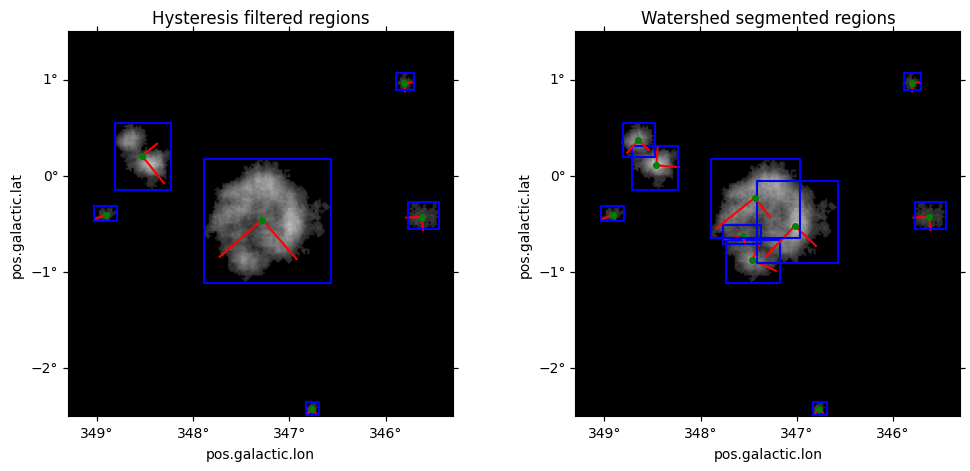

In [21]:
sig_rcorr0p1_fil_cut = sig_rcorr0p1_fil.cutout(
        sig_rcorr0p1_fil.geom.center_skydir, width=np.max(sig_rcorr0p1_fil.geom.width) - 2 * margin
    )
geom_cut = sig_rcorr0p1_fil_cut.geom

plt.show()
plt.figure(figsize=(12,5))
ax1 = plt.subplot(121, projection=geom_cut.wcs)
ax1.imshow(sig_rcorr0p1_fil_cut, cmap=plt.cm.gray, vmax=15)
plot_region_props(props_generator, ax1)
ax1.set_title("Hysteresis filtered regions")

ax2 = plt.subplot(122, projection=geom_cut.wcs)
ax2.imshow(sig_rcorr0p1_fil_cut, cmap=plt.cm.gray, vmax=15)
plot_region_props(props_generator_watershed, ax2)
ax2.set_title("Watershed segmented regions")

We can merge both table and add information in degree

In [22]:
from astropy.table import Table, vstack, unique
candidates_table = unique(vstack([Table(props_table), Table(props_table_watershed)]))


In [23]:
pix_scale = geom_cut.pixel_scales[0]
candidates_table["glon"], candidates_table["glat"] = geom_cut.pix_to_coord((candidates_table["centroid-1"], candidates_table["centroid-0"]))
candidates_table["r_minor"] = candidates_table["axis_minor_length"]*pix_scale/2.
candidates_table["r_major"] = candidates_table["axis_major_length"]*pix_scale/2
candidates_table["r_mean"] = (candidates_table["r_minor"]+candidates_table["r_major"])/2.

we can add associations to H.E.S.S. sources

In [24]:
candidates_coords = SkyCoord(candidates_table["glon"], candidates_table["glat"], frame="galactic")

n_rows = len(candidates_table)
candidates_table["asso"]=np.zeros(n_rows, dtype="U20")
candidates_table["asso_sep"]=np.zeros(n_rows, dtype=float)*u.deg*np.nan

models_hgps_geom = Models.read("./datasets/rxj/models/hgps_rxj_models.yaml")
for m in models_hgps_geom:
    sep = m.position.separation(candidates_coords)
    idx = np.argmin(sep)
    if sep[idx]<0.1*u.deg:
        candidates_table["asso"][idx] = m.name
        candidates_table["asso_sep"].quantity[idx] = sep[idx]


and a flag to identify isolated objects

In [25]:
candidates_table["isolated"]=np.zeros(n_rows, dtype=bool)
for idx in range(n_rows):
    others = np.arange(n_rows)!=idx
    candidates_table["isolated"][idx] = np.all(candidates_coords[idx].separation(
        candidates_coords[others])> candidates_table["r_mean"][idx]+ candidates_table["r_mean"][others])

Let's reorder the table and display

In [26]:
candidates_table = candidates_table[["glon", "glat", "r_mean", "r_minor", "r_major", "asso", "asso_sep", "isolated", "centroid-1", "centroid-0", "axis_minor_length",  "axis_major_length"]]
candidates_table

glon,glat,r_mean,r_minor,r_major,asso,asso_sep,isolated,centroid-1,centroid-0,axis_minor_length,axis_major_length
deg,deg,deg,deg,deg,,deg,,,,,
float64,float64,float64,float64,float64,str20,float64,bool,float64,float64,float64,float64
346.77051429613454,-2.423771760679331,0.06330967949171845,0.056111545079430836,0.07050781390400605,,nan,True,125.96551724137932,3.310344827586207,5.611154507943083,7.050781390400606
347.46297739360796,-0.875100616731946,0.2205019359382115,0.17211858634939955,0.26888528552702345,,nan,False,91.35190615835778,80.74486803519062,17.211858634939954,26.888528552702343
347.555510810804,-0.6258728911553456,0.145393014165827,0.09091367811904488,0.19987235021260916,,nan,False,86.72519083969466,93.20610687022901,9.091367811904489,19.987235021260915
347.01990443383033,-0.5203301602098209,0.3668262561463103,0.3021907124883315,0.4314617998042891,,nan,False,113.50420168067227,98.48319327731092,30.219071248833153,43.14617998042891
347.2820276382962,-0.45668599780013497,0.5649490504917172,0.5425824923055226,0.5873156086779118,HESS J1713-397,0.02883111501457453,False,100.39858979676482,101.66569888013272,54.25824923055225,58.73156086779118
345.621734481749,-0.4246321550660945,0.15253178660815409,0.13920225770890998,0.16586131550739822,HESS J1708-410,0.050969969256821165,True,183.41104294478527,103.25766871165644,13.920225770890998,16.58613155073982
348.91121474313655,-0.40588075391180123,0.08738849981567168,0.06428771841104772,0.11048928122029565,HESS J1718-385,0.07832919444812894,True,18.941176470588236,104.19607843137256,6.428771841104772,11.048928122029565
347.4360380504056,-0.22827619959055892,0.38265158193884985,0.2536124990259499,0.5116906648517497,,nan,False,92.69807497467072,113.08611955420466,25.361249902594988,51.16906648517497


### Sky model creation

Now we can convert that to a gammapy model for our candidates objecs to be fitted.

In [27]:
candidate_models = Models()
for idx in range(n_rows):
    spectral_model = LogParabolaSpectralModel(alpha=2, beta=0, reference=100*u.GeV)
    spectral_model.amplitude.min = 0
    spectral_model.alpha.min = 0
    spectral_model.alpha.max = 5
    spectral_model.beta.min = 0
    spectral_model.beta.max = 1
    spectral_model.beta.frozen = False
    spatial_model = GeneralizedGaussianSpatialModel(lon_0=candidates_table["glon"].quantity[idx],
                                                     lat_0=candidates_table["glat"].quantity[idx],
                                                     r_0=candidates_table["r_mean"].quantity[idx],
                                                     eta=0.5,
                                                     frame="galactic"
                                                    )
    spatial_model.lon_0.min = spatial_model.lon_0.value - candidates_table["r_major"][idx]
    spatial_model.lon_0.max = spatial_model.lon_0.value + candidates_table["r_major"][idx]
    spatial_model.lat_0.min = spatial_model.lat_0.value - candidates_table["r_major"][idx]
    spatial_model.lat_0.max = spatial_model.lat_0.value + candidates_table["r_major"][idx]
    spatial_model.r_0.min = np.maximum(pix_scale.value, candidates_table["r_minor"][idx]/2.)
    spatial_model.r_0.max = candidates_table["r_major"][idx]*2
    spatial_model.eta.min = 0.1
    spatial_model.eta.max = 1.
    spatial_model.eta.frozen = False
    if candidates_table["asso"][idx]=="":
        name = f"Seed_{idx}"
    else:
        name = str(candidates_table["asso"][idx])

    candidate_models.append(SkyModel(spatial_model=spatial_model, spectral_model=spectral_model, name=name))


Let's split them in two list the first one containing the known sources and the isolated objects that we will fit first, and the second containing sub-structures that will be fitted afterward if necessary.

In [28]:
main_selection = (candidates_table["asso"]!="")|(candidates_table["isolated"]==True)
candidate_models_main = candidate_models[main_selection]
candidate_models_sub = candidate_models[~main_selection]

candidate_models_main.write("./datasets/rxj/models/candidate_models_main.yaml", overwrite=True)
candidate_models_sub.write("./datasets/rxj/models/candidate_models_sub.yaml", overwrite=True)

<WCSAxes: >

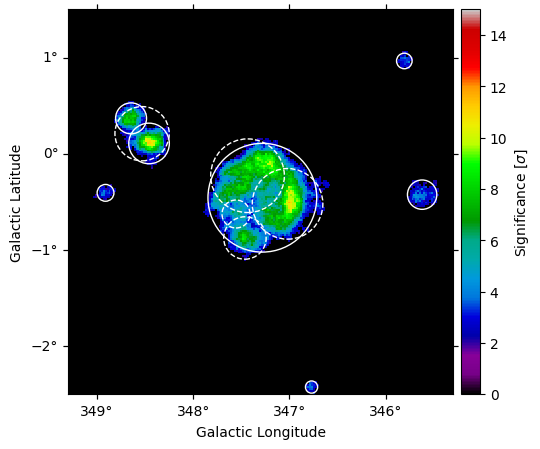

In [29]:
plt.figure(figsize=(7, 5))
ax = plt.subplot(111, projection=fig_geom.wcs)
plot_cutout(sig_rcorr0p1_fil, ax, resi_fil_kwargs)
candidate_models_main.plot_regions(ax=ax, color="w")
candidate_models_sub.plot_regions(ax=ax, color="w", ls="--")

**Next step would be to perform the fit on the joint datasets**